# Lab 2: Data Standardization and Normalization

**Name:** Yashodhara Heggade  
**Reg:** 2427010154  
**Sec:** C/ Batch 1

## Aim
Apply data normalization and standardization to numerical features from the Kaggle Titanic dataset and compare the resulting scales.

## Dataset: Kaggle's Titanic `train.csv`

## 1. Import libraries



In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler

## 2. Load and inspect the data


In [2]:
csv_candidates = [
    Path("/kaggle/input/titanic/train.csv"),
    Path("train.csv"),
    Path("data/train.csv")
]
csv_path = next((path for path in csv_candidates if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        "Could not find train.csv. Download it from the Kaggle Titanic data page and "
        "place it beside this notebook (or in ./data/train.csv). On Kaggle, attach the "
        "dataset so it is available under /kaggle/input/titanic/."
    )

df = pd.read_csv(csv_path)
features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
X = df[features].copy()

print("Loaded file:", csv_path)
print("Dataset shape:", df.shape)
print("Features to scale:", features)
print("\nMissing values in selected features:")
print(X.isnull().sum())
X.head()

Loaded file: train.csv
Dataset shape: (891, 12)
Features to scale: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Missing values in selected features:
Pclass      0
Age       177
SibSp       0
Parch       0
Fare        0
dtype: int64


,Pclass,Age,SibSp,Parch,Fare
0,3,22.0,1,0,7.2500
1,1,38.0,1,0,71.2833
2,3,26.0,0,0,7.9250
3,1,35.0,1,0,53.1000
4,3,35.0,0,0,8.0500


## 3. Handle missing values before scaling

Scalers cannot process missing numerical values. As in Lab 1, we fill missing values in the selected features with each column's mean before scaling. In a real machine-learning workflow, the imputer and scaler should be fitted using only training data, then applied to test data; this notebook demonstrates the transformations on the dataset for learning.

In [3]:
imputer = SimpleImputer(strategy="mean")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X), columns=features, index=X.index
)

print("Missing values after mean imputation:")
print(X_imputed.isnull().sum())
X_imputed.head()

Missing values after mean imputation:
Pclass    0
Age       0
SibSp     0
Parch     0
Fare      0
dtype: int64


,Pclass,Age,SibSp,Parch,Fare
0,3.0,22.0,1.0,0.0,7.2500
1,1.0,38.0,1.0,0.0,71.2833
2,3.0,26.0,0.0,0.0,7.9250
3,1.0,35.0,1.0,0.0,53.1000
4,3.0,35.0,0.0,0.0,8.0500


## 4. Original feature scales

The features use different units and ranges. For example, Fare is measured in money, while Pclass is a small category code. Comparing raw values directly can give large-scale features more influence in some algorithms.

In [4]:
X_imputed.describe().round(2)

,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,891.00,891.00
mean,2.31,29.70,0.52,0.38,32.20
std,0.84,13.00,1.10,0.81,49.69
min,1.00,0.42,0.00,0.00,0.00
25%,2.00,22.00,0.00,0.00,7.91
50%,3.00,29.70,0.00,0.00,14.45
75%,3.00,35.00,1.00,0.00,31.00
max,3.00,80.00,8.00,6.00,512.33


## 5. Min-Max normalization



In [5]:
minmax_scaler = MinMaxScaler()
X_normalized = pd.DataFrame(
    minmax_scaler.fit_transform(X_imputed),
    columns=features, index=X.index
)

print("Normalized feature ranges:")
print("Minimum values:")
print(X_normalized.min().round(3))
print("\nMaximum values:")
print(X_normalized.max().round(3))
X_normalized.head()

Normalized feature ranges:
Minimum values:
Pclass    0.0
Age       0.0
SibSp     0.0
Parch     0.0
Fare      0.0
dtype: float64

Maximum values:
Pclass    1.0
Age       1.0
SibSp     1.0
Parch     1.0
Fare      1.0
dtype: float64


,Pclass,Age,SibSp,Parch,Fare
0,1.0,0.271174,0.125,0.0,0.014151
1,0.0,0.472229,0.125,0.0,0.139136
2,1.0,0.321438,0.000,0.0,0.015469
3,0.0,0.434531,0.125,0.0,0.103644
4,1.0,0.434531,0.000,0.0,0.015713


## 6. Z-score standardization



In [6]:
standard_scaler = StandardScaler()
X_standardized = pd.DataFrame(
    standard_scaler.fit_transform(X_imputed),
    columns=features, index=X.index
)

print("Standardized feature means (approximately 0):")
print(X_standardized.mean().round(3))
print("\nStandardized feature standard deviations (approximately 1):")
print(X_standardized.std(ddof=0).round(3))
X_standardized.head()

Standardized feature means (approximately 0):
Pclass   -0.0
Age       0.0
SibSp     0.0
Parch     0.0
Fare      0.0
dtype: float64

Standardized feature standard deviations (approximately 1):
Pclass    1.0
Age       1.0
SibSp     1.0
Parch     1.0
Fare      1.0
dtype: float64


,Pclass,Age,SibSp,Parch,Fare
0,0.827377,-0.592481,0.432793,-0.473674,-0.502445
1,-1.566107,0.638789,0.432793,-0.473674,0.786845
2,0.827377,-0.284663,-0.474545,-0.473674,-0.488854
3,-1.566107,0.407926,0.432793,-0.473674,0.420730
4,0.827377,0.407926,-0.474545,-0.473674,-0.486337


## 7. Compare the transformed data



In [7]:
def scale_summary(data, method):
    summary = data.agg(["min", "max", "mean", "std"]).T
    summary.insert(0, "Method", method)
    return summary

comparison = pd.concat([
    scale_summary(X_imputed, "Original after imputation"),
    scale_summary(X_normalized, "Min-Max normalization"),
    scale_summary(X_standardized, "Z-score standardization")
])
comparison.round(3)

,Method,min,max,mean,std
Pclass,Original after imputation,1.000,3.000,2.309,0.836
Age,Original after imputation,0.420,80.000,29.699,13.002
SibSp,Original after imputation,0.000,8.000,0.523,1.103
Parch,Original after imputation,0.000,6.000,0.382,0.806
Fare,Original after imputation,0.000,512.329,32.204,49.693
Pclass,Min-Max normalization,0.000,1.000,0.654,0.418
Age,Min-Max normalization,0.000,1.000,0.368,0.163
SibSp,Min-Max normalization,0.000,1.000,0.065,0.138
Parch,Min-Max normalization,0.000,1.000,0.064,0.134
Fare,Min-Max normalization,0.000,1.000,0.063,0.097


## 8. Plot feature distributions



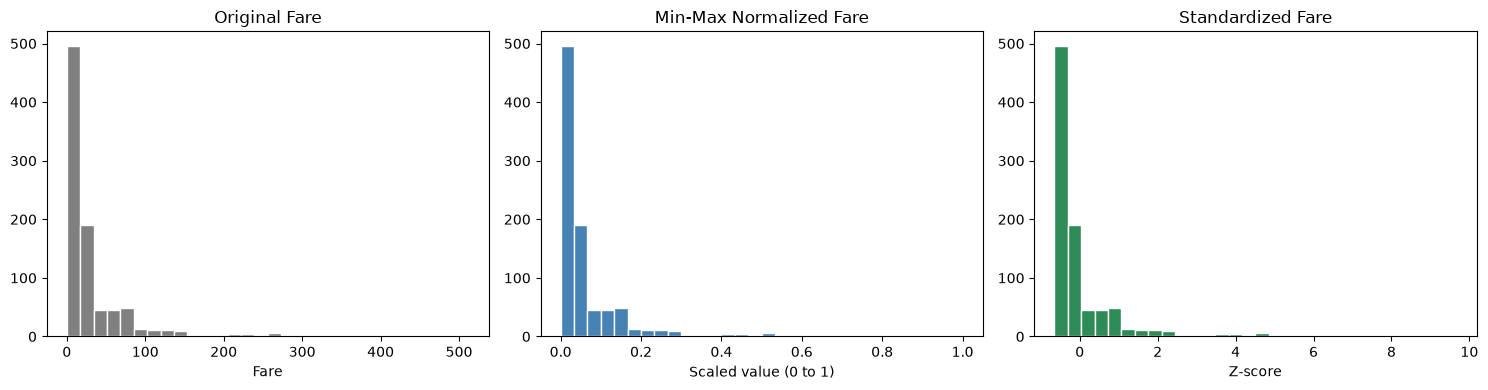

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(X_imputed["Fare"], bins=30, color="gray", edgecolor="white")
axes[0].set_title("Original Fare")
axes[0].set_xlabel("Fare")

axes[1].hist(X_normalized["Fare"], bins=30, color="steelblue", edgecolor="white")
axes[1].set_title("Min-Max Normalized Fare")
axes[1].set_xlabel("Scaled value (0 to 1)")

axes[2].hist(X_standardized["Fare"], bins=30, color="seagreen", edgecolor="white")
axes[2].set_title("Standardized Fare")
axes[2].set_xlabel("Z-score")

plt.tight_layout()
plt.show()